# Задание 3.1. Аттрактор Лоренца и горизонт предсказуемости

Исследуется система

$$
\dot x=\sigma(y-x),\qquad
\dot y=x(\rho-z)-y,\qquad
\dot z=xy-\beta z,
$$

где $\sigma=10$, $\beta=8/3$, начальное условие $(1,1,1)$. Рассматриваются $\rho=28$ (хаотический режим) и $\rho=10$ (устойчивое равновесие).

Для интегрирования используется метод **DOP853** (Метод Рунге-Кутта 8ого порядка) с адаптивным шагом из `scipy.integrate.solve_ivp`. Фиксированная сетка используетя для построения графиков; `max_step`, `rtol` и `atol` контролируют работу интегратора.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image

SIGMA = 10.0
BETA = 8.0 / 3.0
U0 = np.array([1.0, 1.0, 1.0])

plt.rcParams.update({
    "figure.figsize": (11, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 110,
    "font.size": 10,
})

def lorenz(t, u, rho):
    x, y, z = u
    return np.array([
        SIGMA * (y - x),
        x * (rho - z) - y,
        x * y - BETA * z,
    ])

def integrate(u0, rho, t_end, step=0.02, rtol=1e-10,
              atol=1e-12, max_step=0.05):
    t_grid = np.linspace(0, t_end, round(t_end / step) + 1)
    sol = solve_ivp(
        lorenz, (0, t_end), u0, args=(rho,), method="DOP853",
        t_eval=t_grid, rtol=rtol, atol=atol, max_step=max_step,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.t, sol.y.T

/usr/local/lib/python3.12/dist-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Временные ряды и фазовые портреты

Для каждого значения $\rho$ интегрируем систему из точки $(1,1,1)$. На временных рядах виден переходный процесс, а на фазовых портретах — дальнейшее движение. При $\rho=10$ траектория приближается к устойчивой точке; при $\rho=28$ остаётся на сложном ограниченном множестве.

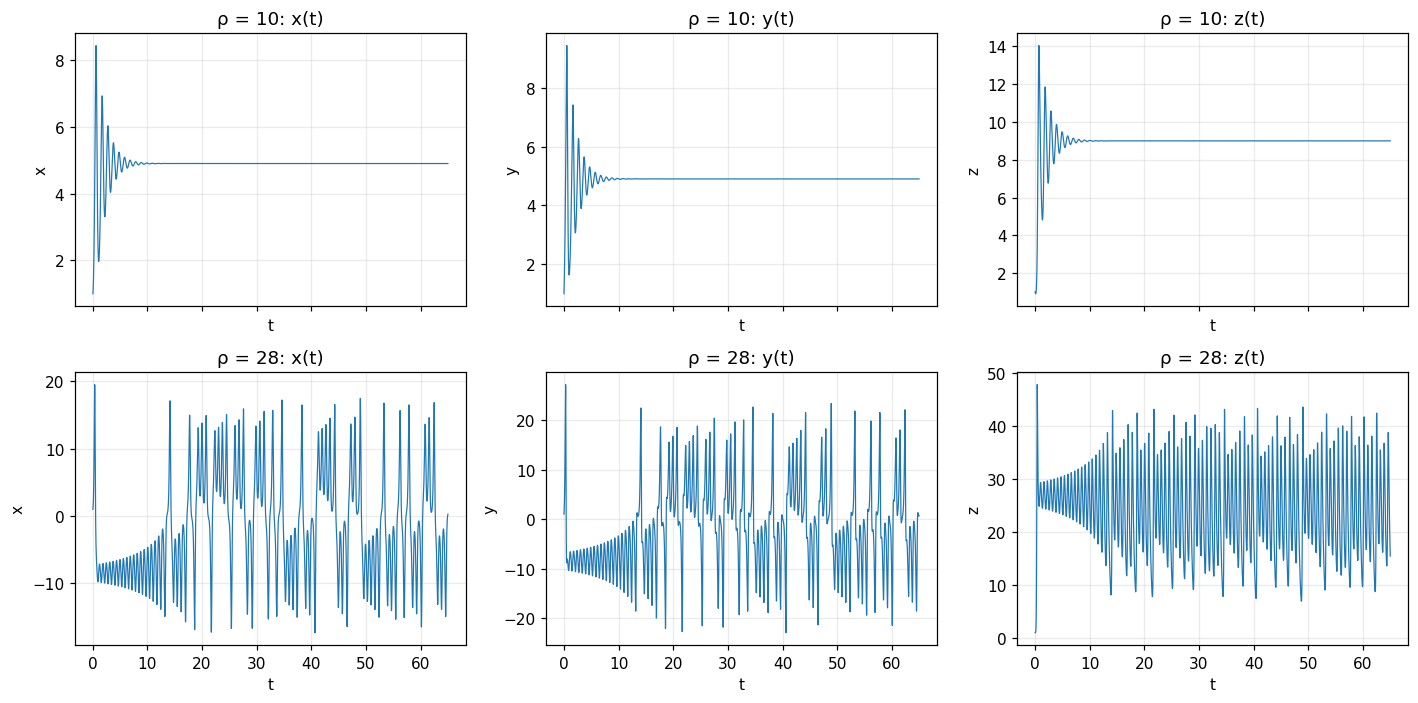

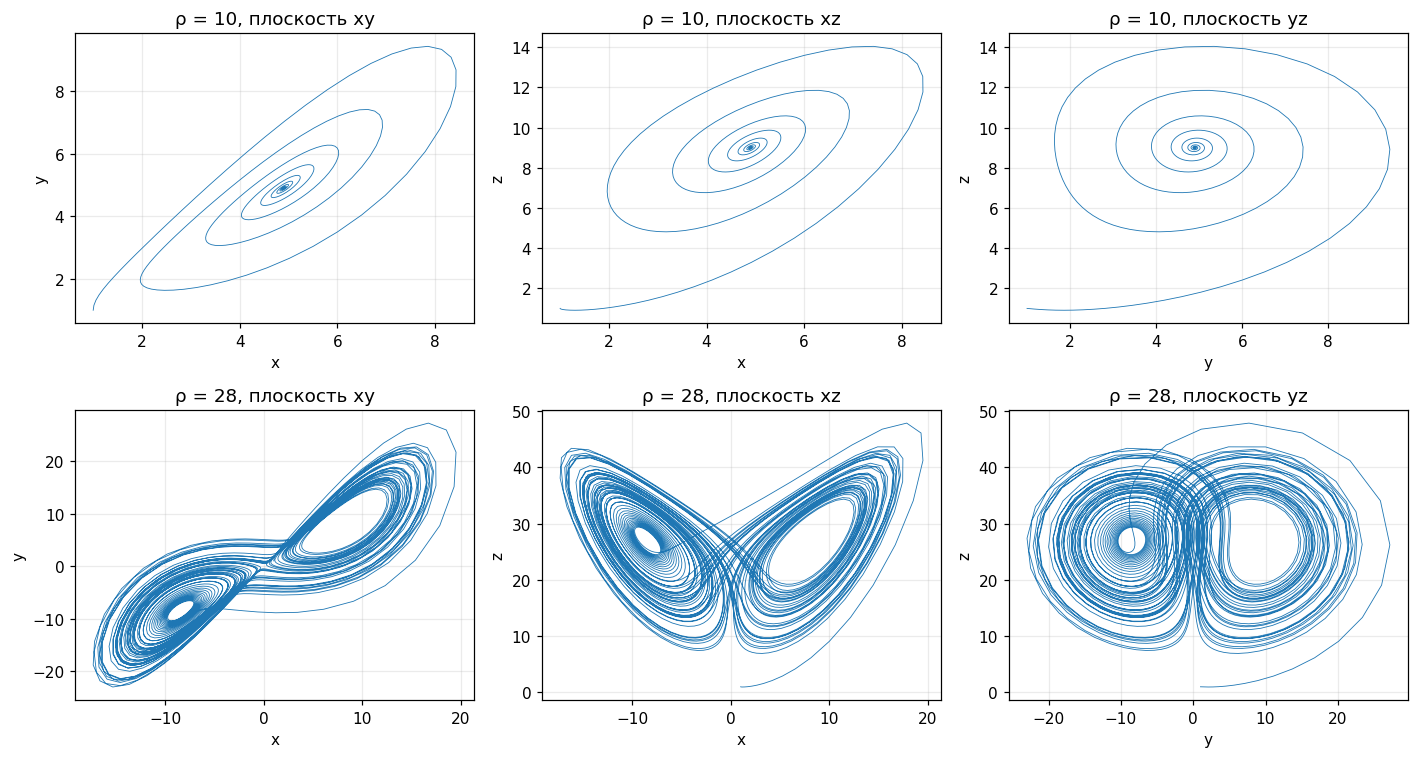

In [2]:
trajectories = {}
for rho in [10, 28]:
    trajectories[rho] = integrate(U0, rho, t_end=65)

fig, axs = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for i, rho in enumerate([10, 28]):
    t, u = trajectories[rho]
    for j, name in enumerate(["x", "y", "z"]):
        axs[i, j].plot(t, u[:, j], lw=0.8)
        axs[i, j].set_title(f"ρ = {rho}: {name}(t)")
        axs[i, j].set_xlabel("t")
        axs[i, j].set_ylabel(name)
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(2, 3, figsize=(13, 7))
projections = [(0, 1), (0, 2), (1, 2)]
labels = ["x", "y", "z"]
for i, rho in enumerate([10, 28]):
    _, u = trajectories[rho]
    for j, (a, b) in enumerate(projections):
        axs[i, j].plot(u[:, a], u[:, b], lw=0.55)
        axs[i, j].set_title(f"ρ = {rho}, плоскость {labels[a]}{labels[b]}")
        axs[i, j].set_xlabel(labels[a])
        axs[i, j].set_ylabel(labels[b])
plt.tight_layout()
plt.show()

## 2. Разбегание близких траекторий

После переходного процесса ($t=30$) выбираем точку опорной траектории при $\rho=28$. Вторую траекторию начинаем из $(x+\delta_0,y,z)$, где $\delta_0=10^{-6}$. Измеряем расстояние

$$d(t)=\sqrt{(x_1-x_2)^2+(y_1-y_2)^2+(z_1-z_2)^2}.$$

Обе системы интегрируются **совместно** как одна шестимерная система. Это исключает искусственное различие внутренних сеток решателя для двух близких траекторий.

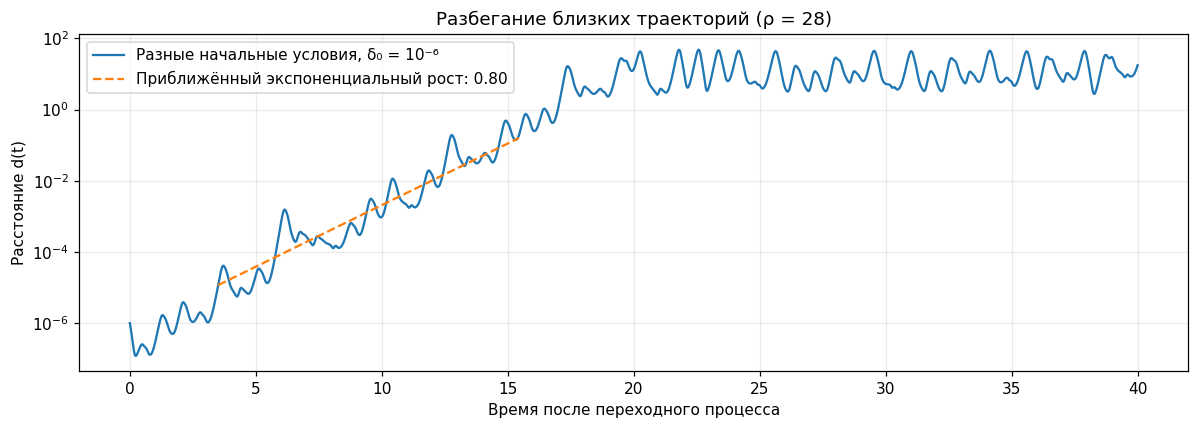

In [3]:
BURN_TIME = 30.0
burn = solve_ivp(lorenz, (0, BURN_TIME), U0, args=(28,),
                 method="DOP853", rtol=1e-12, atol=1e-14, max_step=0.04)
u_start = burn.y[:, -1].copy()

def pair_rhs(t, q, rho):
    return np.r_[lorenz(t, q[:3], rho), lorenz(t, q[3:], rho)]

def integrate_pair(u0, rho=28, delta=1e-6, t_end=40.0,
                   step=0.02, rtol=1e-11, atol=1e-13, max_step=0.05):
    shifted = u0 + np.array([delta, 0.0, 0.0])
    t_grid = np.linspace(0, t_end, round(t_end / step) + 1)
    sol = solve_ivp(pair_rhs, (0, t_end), np.r_[u0, shifted],
                    args=(rho,), method="DOP853", t_eval=t_grid,
                    rtol=rtol, atol=atol, max_step=max_step)
    if not sol.success:
        raise RuntimeError(sol.message)
    p, q = sol.y[:3].T, sol.y[3:].T
    distance = np.linalg.norm(p - q, axis=1)
    return sol.t, p, q, distance

t_pair, u_ref, u_close, d_pair = integrate_pair(u_start)

fig, ax = plt.subplots(figsize=(11, 4))
ax.semilogy(t_pair, d_pair, label="Разные начальные условия, δ₀ = 10⁻⁶")
# Начальный участок с ростом расстояния на порядки величины.
mask = (t_pair > 1) & (d_pair > 1e-5) & (d_pair < 0.2)
if mask.sum() > 20:
    slope, intercept = np.polyfit(t_pair[mask], np.log(d_pair[mask]), 1)
    xx = t_pair[mask]
    ax.semilogy(xx, np.exp(intercept + slope * xx), "--",
                label=f"Приближённый экспоненциальный рост: {slope:.2f}")
ax.set(xlabel="Время после переходного процесса", ylabel="Расстояние d(t)",
       title="Разбегание близких траекторий (ρ = 28)")
ax.legend()
plt.tight_layout()
plt.show()

Проверим влияние точности интегратора: решаем **одну и ту же** задачу с одинаковым начальным условием, но с разными допусками. Различие решений сначала мало, затем тоже усиливается из-за чувствительности хаотической системы.

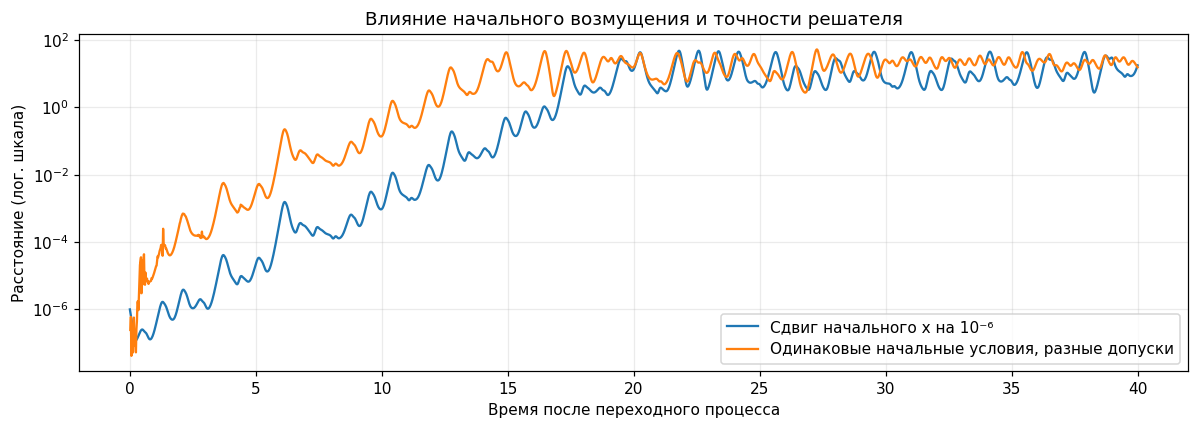

In [4]:
# Нулевое начальное отличие: расхождение связано только с численной погрешностью.
t_fine, u_fine = integrate(u_start, 28, t_end=40, rtol=1e-12,
                           atol=1e-14, max_step=0.03)
t_loose, u_loose = integrate(u_start, 28, t_end=40, rtol=1e-6,
                             atol=1e-9, max_step=0.15)
d_numeric = np.linalg.norm(u_fine - u_loose, axis=1)

fig, ax = plt.subplots(figsize=(11, 4))
ax.semilogy(t_pair, d_pair, label="Сдвиг начального x на 10⁻⁶")
ax.semilogy(t_fine[1:], d_numeric[1:], label="Одинаковые начальные условия, разные допуски")
ax.set(xlabel="Время после переходного процесса", ylabel="Расстояние (лог. шкала)",
       title="Влияние начального возмущения и точности решателя")
ax.legend()
plt.tight_layout()
plt.show()

На начальном участке $\ln d(t)$ в среднем растёт приблизительно линейно, что соответствует $d(t)\sim d_0e^{\lambda t}$. Позже расстояние колеблется около размеров аттрактора: отдельные траектории расходятся, но обе остаются в ограниченной области фазового пространства. Поэтому неограниченного экспоненциального роста расстояния нет. Уменьшение численной ошибки отодвигает разбегание расчётов, но не устраняет его.

## 3. Старший показатель Ляпунова

Используем метод двух траекторий с периодической перенормировкой. В начале расстояние равно $\delta_0$. Через фиксированный интервал $\tau$ вычисляем $d_k$, добавляем $\ln(d_k/\delta_0)$ к сумме и снова устанавливаем расстояние $\delta_0$ в направлении текущего возмущения. Накопленная оценка:

$$\lambda_{\max}(T)=\frac{1}{T}\sum_{k=1}^{N}\ln\frac{d_k}{\delta_0},\qquad T=N\tau.$$

Перенормировка не даёт расстоянию выйти из линейной области и позволяет накапливать скорость растяжения на длинном интервале.

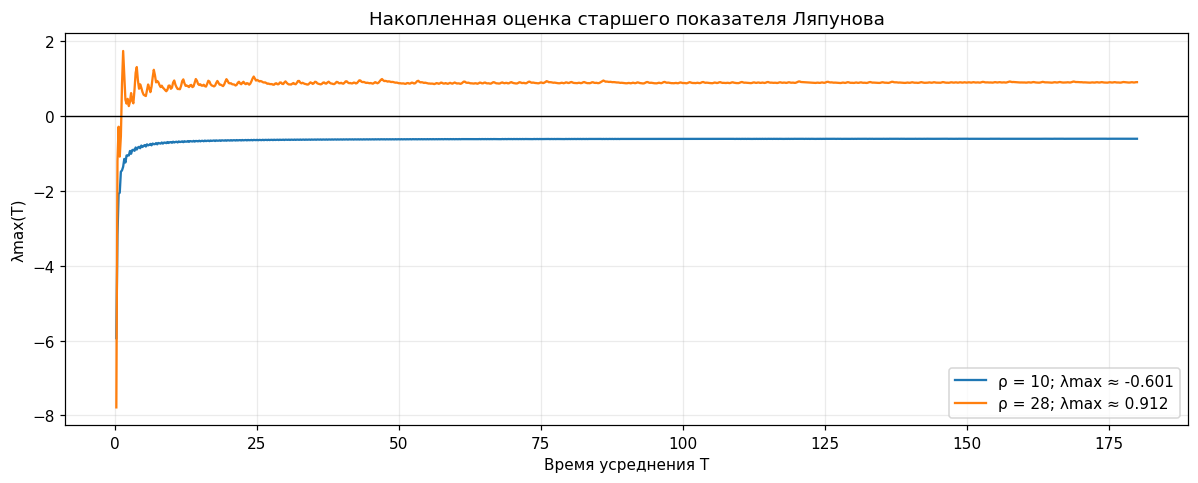

ρ = 10: λmax ≈ -0.6014
ρ = 28: λmax ≈ 0.9123


In [5]:
def lyapunov(rho, T=180.0, delta0=1e-7, tau=0.2,
             rtol=3e-10, atol=3e-12, max_step=0.05):
    n = round(T / tau)
    if not np.isclose(n * tau, T):
        raise ValueError("T должно быть кратно tau")
    warm = solve_ivp(lorenz, (0, BURN_TIME), U0,
                     args=(rho,), method="DOP853", rtol=rtol,
                     atol=atol, max_step=max_step)
    base = warm.y[:, -1].copy()
    shadow = base + np.array([delta0, 0.0, 0.0])
    acc = 0.0
    estimates = np.empty(n)
    for k in range(n):
        ans = solve_ivp(pair_rhs, (0, tau), np.r_[base, shadow],
                        args=(rho,), method="DOP853", rtol=rtol,
                        atol=atol, max_step=max_step)
        if not ans.success:
            raise RuntimeError(ans.message)
        base = ans.y[:3, -1]
        shadow = ans.y[3:, -1]
        difference = shadow - base
        distance = np.linalg.norm(difference)
        acc += np.log(distance / delta0)
        shadow = base + delta0 * difference / distance
        estimates[k] = acc / ((k + 1) * tau)
    return np.arange(1, n + 1) * tau, estimates

lyap = {rho: lyapunov(rho) for rho in [10, 28]}
lambda10 = lyap[10][1][-1]
lambda28 = lyap[28][1][-1]

fig, ax = plt.subplots(figsize=(11, 4.5))
for rho in [10, 28]:
    t, values = lyap[rho]
    ax.plot(t, values, label=f"ρ = {rho}; λmax ≈ {values[-1]:.3f}")
ax.axhline(0, lw=0.9, color="black")
ax.set(xlabel="Время усреднения T", ylabel="λmax(T)",
       title="Накопленная оценка старшего показателя Ляпунова")
ax.legend()
plt.tight_layout()
plt.show()
print(f"ρ = 10: λmax ≈ {lambda10:.4f}")
print(f"ρ = 28: λmax ≈ {lambda28:.4f}")

Для $\rho=10$ после переходного процесса решение стремится к одному из устойчивых равновесий $(\pm\sqrt{\beta(\rho-1)},\pm\sqrt{\beta(\rho-1)},\rho-1)$. Проверим отрицательный показатель по собственным значениям матрицы Якоби в таком равновесии.

In [6]:
rho = 10
x_star = np.sqrt(BETA * (rho - 1))
J = np.array([
    [-SIGMA, SIGMA, 0],
    [rho - (rho - 1), -1, -x_star],
    [x_star, x_star, -BETA],
])
reals = np.linalg.eigvals(J).real
print(f"ρ = 10: max Re(eig(J)) = {reals.max():.4f}; "
      f"численная оценка = {lambda10:.4f}")

ρ = 10: max Re(eig(J)) = -0.5955; численная оценка = -0.6014


### Проверка устойчивости оценки

Меняем по отдельности длительность усреднения, исходное расстояние, интервал перенормировки и точность интегратора. Конечные оценки для хаотического режима не должны совпадать до последнего знака: они зависят от длины конечной траектории.

In [7]:
checks = [
    ("Основной расчёт", dict(T=180, delta0=1e-7, tau=0.2,
                             rtol=3e-10, atol=3e-12)),
    ("T = 90", dict(T=90, delta0=1e-7, tau=0.2,
                     rtol=3e-10, atol=3e-12)),
    ("δ₀ = 10⁻⁶", dict(T=180, delta0=1e-6, tau=0.2,
                          rtol=3e-10, atol=3e-12)),
    ("δ₀ = 10⁻⁸", dict(T=180, delta0=1e-8, tau=0.2,
                          rtol=3e-10, atol=3e-12)),
    ("τ = 0.1", dict(T=180, delta0=1e-7, tau=0.1,
                      rtol=3e-10, atol=3e-12)),
    ("τ = 0.4", dict(T=180, delta0=1e-7, tau=0.4,
                      rtol=3e-10, atol=3e-12)),
    ("Менее строгие допуски", dict(T=180, delta0=1e-7, tau=0.2,
                                     rtol=1e-8, atol=1e-10)),
    ("Более строгие допуски", dict(T=180, delta0=1e-7, tau=0.2,
                                     rtol=1e-11, atol=1e-13)),
]
rows = []
for description, params in checks:
    if description == "Основной расчёт":
        value = lambda28
    else:
        _, history = lyapunov(28, **params)
        value = history[-1]
    rows.append({"Настройки": description, "λmax": round(value, 4),
                 "Отличие от базовой": round(value - lambda28, 4)})
display(pd.DataFrame(rows))

,Настройки,λmax,Отличие от базовой
0,Основной расчёт,0.9123,0.0000
1,T = 90,0.8821,-0.0301
2,δ₀ = 10⁻⁶,0.9232,0.0109
3,δ₀ = 10⁻⁸,0.8998,-0.0125
4,τ = 0.1,0.8888,-0.0234
5,τ = 0.4,0.9075,-0.0048
6,Менее строгие допуски,0.9347,0.0225
7,Более строгие допуски,0.9090,-0.0033


## 4. Горизонт предсказуемости

Выберем порог заметной ошибки $\Delta=1$, что значительно меньше типичного размера аттрактора. При начальной ошибке $\delta_0$ линейная оценка даёт

$$T_{\rm pred}\approx \frac{\ln(\Delta/\delta_0)}{\lambda_{\max}}.$$

Для сравнения численно находим **первый момент**, когда $d(t)\geq\Delta$, у нескольких пар близких траекторий **без перенормировки**. Время начала измеряется от точки после переходного процесса.

,δ₀,T: численно,T: по λmax
0,1e-04,10.38,10.10
1,1e-05,12.65,12.62
2,1e-06,16.41,15.14
3,1e-07,17.25,17.67
4,1e-08,21.60,20.19


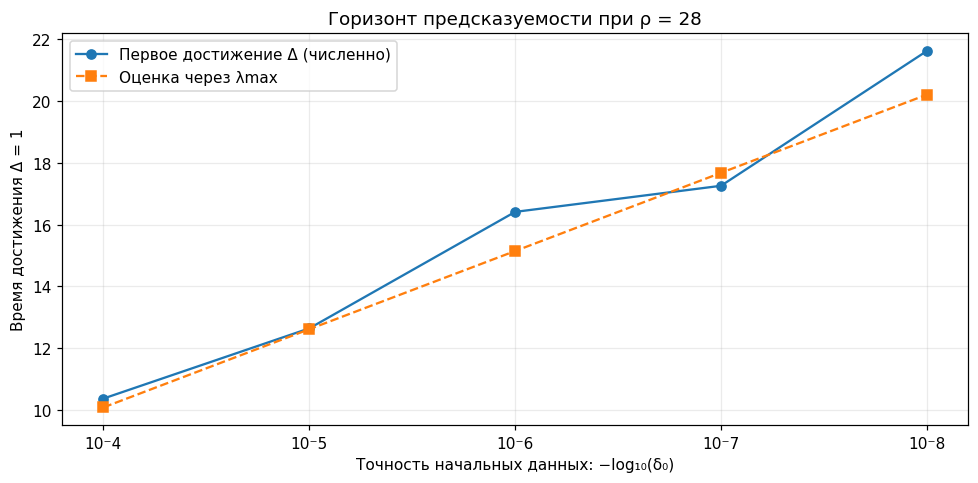

Уменьшение δ₀ в 10 раз: теория даёт +2.52 ед. времени.
Для пары 10⁻⁶ → 10⁻⁷: численно +0.84 ед. времени.


In [8]:
DELTA = 1.0
initial_gaps = np.array([1e-4, 1e-5, 1e-6, 1e-7, 1e-8])

def first_crossing(t, distances, level):
    indices = np.flatnonzero(distances >= level)
    if len(indices) == 0:
        return np.nan
    k = int(indices[0])
    if k == 0:
        return t[0]
    # Интерполяция момента пересечения между соседними отсчётами.
    return t[k-1] + (level-distances[k-1]) * (t[k]-t[k-1]) / (distances[k]-distances[k-1])

horizon_rows = []
pairs = {}
for gap in initial_gaps:
    tt, aa, bb, dd = integrate_pair(u_start, delta=gap, t_end=40, step=0.02)
    pairs[gap] = (tt, aa, bb, dd)
    measured = first_crossing(tt, dd, DELTA)
    predicted = np.log(DELTA / gap) / lambda28
    horizon_rows.append({
        "δ₀": gap, "T: численно": measured, "T: по λmax": predicted
    })
horizons = pd.DataFrame(horizon_rows)
display(horizons.style.format({"δ₀": "{:.0e}",
                               "T: численно": "{:.2f}",
                               "T: по λmax": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = -np.log10(initial_gaps)
ax.plot(x, horizons["T: численно"], "o-", label="Первое достижение Δ (численно)")
ax.plot(x, horizons["T: по λmax"], "s--", label="Оценка через λmax")
ax.set(xlabel="Точность начальных данных: −log₁₀(δ₀)",
       ylabel="Время достижения Δ = 1",
       title="Горизонт предсказуемости при ρ = 28")
ax.set_xticks(x, [f"10⁻{int(k)}" for k in x])
ax.legend()
plt.tight_layout()
plt.show()

extra_time = np.log(10) / lambda28
measured_extra = (horizons.loc[horizons["δ₀"] == 1e-7, "T: численно"].iloc[0]
                  - horizons.loc[horizons["δ₀"] == 1e-6, "T: численно"].iloc[0])
print(f"Уменьшение δ₀ в 10 раз: теория даёт +{extra_time:.2f} ед. времени.")
print(f"Для пары 10⁻⁶ → 10⁻⁷: численно +{measured_extra:.2f} ед. времени.")

**Вывод.** В хаотическом режиме точность прогноза ограничена положительным старшим показателем Ляпунова. Уменьшение начальной ошибки в 10 раз увеличивает расчётный горизонт лишь на $\ln(10)/\lambda_{\max}$, то есть примерно на несколько единиц времени, а не в 10 раз. Реальное первое достижение порога отличается от средней оценки из-за неравномерного локального растяжения траекторий. При $\rho=10$ старший показатель отрицателен, малые возмущения затухают, поэтому хаотическая формула горизонта там неприменима.

## 5. Анимация расхождения

Слева одновременно показаны две траектории в проекции $xy$ (последние несколько единиц времени), справа — то же движение на графике расстояния. Метка на правом графике соответствует текущему кадру.


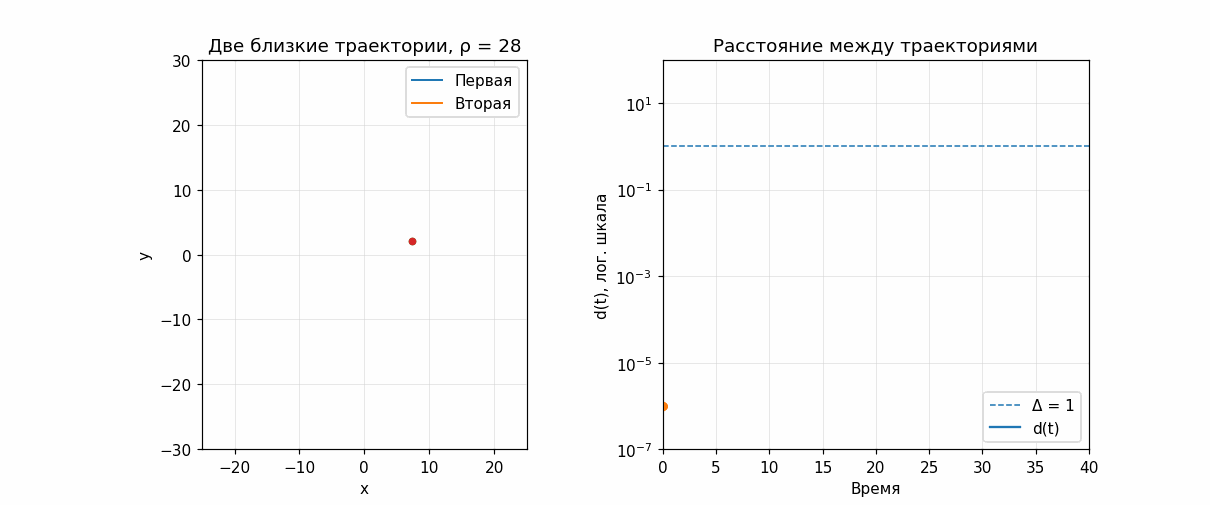

In [9]:
# Для анимации используем пару с исходным расстоянием 10⁻⁶.
t_anim, a_anim, b_anim, d_anim = pairs[1e-6]
fig, (ax_xy, ax_d) = plt.subplots(1, 2, figsize=(11, 4.6))
ax_xy.set(xlim=(-25, 25), ylim=(-30, 30), xlabel="x", ylabel="y",
          title="Две близкие траектории, ρ = 28")
ax_xy.set_aspect("equal", adjustable="box")
line_a, = ax_xy.plot([], [], lw=1.3, label="Первая")
line_b, = ax_xy.plot([], [], lw=1.3, label="Вторая")
point_a, = ax_xy.plot([], [], "o", ms=4)
point_b, = ax_xy.plot([], [], "o", ms=4)
ax_xy.legend(loc="upper right")

ax_d.set(xlim=(0, 40), ylim=(1e-7, 100), xlabel="Время",
         ylabel="d(t), лог. шкала", title="Расстояние между траекториями")
ax_d.set_yscale("log")
ax_d.axhline(DELTA, ls="--", lw=1, label="Δ = 1")
line_d, = ax_d.plot([], [], lw=1.5, label="d(t)")
point_d, = ax_d.plot([], [], "o", ms=5)
ax_d.legend(loc="lower right")

frame_indices = np.linspace(0, len(t_anim)-1, 110, dtype=int)
tail = 350  # отображаем последние 7 единиц времени

def update(frame):
    k = int(frame_indices[frame])
    start = max(0, k - tail)
    line_a.set_data(a_anim[start:k+1, 0], a_anim[start:k+1, 1])
    line_b.set_data(b_anim[start:k+1, 0], b_anim[start:k+1, 1])
    point_a.set_data([a_anim[k, 0]], [a_anim[k, 1]])
    point_b.set_data([b_anim[k, 0]], [b_anim[k, 1]])
    line_d.set_data(t_anim[:k+1], d_anim[:k+1])
    point_d.set_data([t_anim[k]], [d_anim[k]])
    return line_a, line_b, point_a, point_b, line_d, point_d

anim = FuncAnimation(fig, update, frames=len(frame_indices), interval=90, blit=True)
# GIF создаётся во временной папке и сразу встраивается в вывод ячейки.
# После сохранения notebook никакой отдельный файл не требуется.
from pathlib import Path
from tempfile import TemporaryDirectory

with TemporaryDirectory() as temp_dir:
    gif_path = Path(temp_dir) / "lorenz.gif"
    anim.save(str(gif_path), writer=PillowWriter(fps=12))
    gif_data = gif_path.read_bytes()
plt.close(fig)
display(Image(data=gif_data, format="gif"))

### Итог

- При $\rho=28$ расстояние между близкими решениями сначала растёт в среднем экспоненциально, затем ограничивается масштабом аттрактора.
- При $\rho=10$ старший показатель Ляпунова отрицателен; при $\rho=28$ — положителен.
- Ужесточение допусков решателя уменьшает численную ошибку, но не отменяет чувствительность хаотической системы.
- Горизонт предсказуемости зависит от начальной точности **логарифмически**.